In [1]:
import recap
import pickle
import rdkit
from rdkit import Chem
import matplotlib.pyplot as plt
import networkx as nx
import ipycytoscape
import time
import warnings
from urllib import parse
from rdkit.Chem.Draw import IPythonConsole, MolsToGridImage
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem import rdChemReactions as Reactions
from IPython.display import display
warnings.filterwarnings('ignore')

In [2]:
# Load data

with open('../recap-delivery/data/BUL_ddd.pkl', 'rb') as f:
    BUL = pickle.load(f)

In [3]:
# Load data

with open('../metabolic-disassembler-delivery/to_metadisassembler_v3/indexer_original_mols.pkl', 'rb') as f:
    indexer = pickle.load(f)
indexer = {v:k for k, v in indexer.items()}

In [4]:
# These are the definitions that will be applied to fragment molecules:

# They include the originally defined reaction rules in RECAP and
# the modified version with the openning ring capability. 

# They keep the dummy atoms.
 
reactionDefs = (
  "[#7;+0;D2,D3:1]!@C(!@=O)!@[#7;+0;D2,D3:2]>>[#7:1].[#7:2]", # urea + bicarbonato CHECK
  "[#7;+0;D2,D3:1]C(!@=O)[#7;+0;D2,D3:2]>>([#7:1].[#7:2])", # urea ring

  "[C;!$(C([#7])[#7]):1](=!@[O:2])!@[#7;+0;!D1:3]>>O[C:1]=[O:2].[#7:3]",  # amide not cyclic
  "[C;!$(C([#7])[#7]):1](=[O:2])[#7;+0;!D1:3]>>(O[C:1]=[O:2].[#7:3])", # amide macrocycles

  "[*:4][C:1](=!@[O:2])!@[O;+0:3][*:5]>>[*:4][C:1](O)=[O:2].[O:3][*:5]", # ester !!!!!!!!!!!!
  "[*:4][C:1](=!@[O:2])[O;+0:3]>>([*:4][C:1](O)=[O:2].[O:3])", # ester ring

  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-!@[*:1])-!@[*:2]>>[*:1].[*:2]", # amines + amoniaco(?) CHECK
  "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-[*:1])-[*:2]>>([*:1].[*:2])", # amines ring
  #"[N;!D1](!@[*:1])!@[*:2]>>[*][*:1].[*:2][*]", # amines

  # again: what about aromatics?
  "[#7;R;D3;+0:1]-!@[*:2]>>[#7:1].[*:2][O]", # cyclic amines CHECK
  "[#7;R;D3;+0:1]-[*:2]>>([#7:1].[*:2][O])", # cyclic amines ring # Seems too general?

  "[#6:1]-!@[O;+0]-!@[#6:2]>>[#6:1][O].[O][#6:2]", # ether CHECK
  "[#6:1]-[O;+0]-[#6:2]>>([#6:1][O].[O][#6:2])", # ether ring

  "[C:1]=!@[C:2]>>[C:1].[C:2]", # olefin
  #"[C:1]=[C:2]>>([C:1][*].[*][C:2])", # olefin ring

  "[n;+0:1]-!@[C:2]>>[n:1].[C:2][*]", # aromatic nitrogen - aliphatic carbon
  #"[n;+0:1]-[C:2]>>([n:1][*].[C:2][*])", # aromatic nitrogen - aliphatic carbon ring

  "[O:3]=[C:4]-@[N;+0:1]-!@[C:2]>>[O:3]=[C:4]-[N:1].[C:2]", # lactam nitrogen - aliphatic carbon
  #"[O:3]=[C:4]-@[N;+0:1]-[C:2]>>([O:3]=[C:4]-[N:1][*].[C:2][*])", # lactam nitrogen - aliphatic carbon ring

  "[c:1]-!@[c:2]>>[c:1].[c:2]", # aromatic carbon - aromatic carbon
  "[c:1]-[c:2]>>([c:1].[c:2])", # aromatic carbon - aromatic carbon ring

  "[n;+0:1]-!@[c:2]>>[n:1].[c:2]", # aromatic nitrogen - aromatic carbon *NOTE* this is not part of the standard recap set.
  "[n;+0:1]-[c:2]>>([n:1].[c:2])", # aromatic nitrogen - aromatic carbon ring *NOTE* this is not part of the standard recap set.

  "[#7;+0;D2,D3:1]-!@[S:2](=[O:3])=[O:4]>>[#7:1].[S:2](=[O:3])=[O:4]", # sulphonamide
  #"[#7;+0;D2,D3:1]-[S:2](=[O:3])=[O:4]>>([#7:1][*].[*][S:2](=[O:3])=[O:4])", # sulphonamide ring
  )

names = ['urea', 'ureaR', 'amide', 'amideR', 'ester', 'esterR', 'amines', 'aminesR', 'cyclicAmines', 'cyclicAminesR',
        'ether', 'etherR', 'olefin', 'arNalC', 'laNalC', 'arCarC', 'arCarCR', 'arNarC',
        'arNarCR', 'sulphonamide']
reactions = dict(zip(names, reactionDefs))
reactionsMol2 = {k: Reactions.ReactionFromSmarts(v) for k, v in reactions.items()}

In [5]:
with open('../metabolic-disassembler-delivery/to_metadisassembler_v3/original_molecules.pkl', 'rb') as f:
    mols = pickle.load(f)

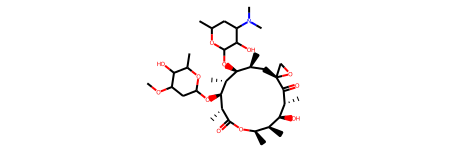

In [6]:
mol = mols[15]
mol

# Start Testing RECAP algorithm

In [7]:
fragmentNet = recap.FragmentNet(mol, reactionsMol2, BUL)

In [8]:
start_time = time.time()
fragmentNet.run_recap(keggAlign=True, useHs=True, verbose=True, forceNPLeaves=False, sanitizeFlag=False)
print("--- %s seconds ---" % (time.time() - start_time))

--- 47.281089305877686 seconds ---


In [9]:
fragmentNet.graph.nodes

NodeView(('COC1CC(O[C@@H]2[C@@H](C)C(=O)O[C@H](C)[C@H](C)[C@H](O)[C@@H](C)C(=O)[C@@]3(CO3)C[C@H](C)[C@H](OC3OC(C)CC(N(C)C)C3O)[C@H]2C)OC(C)C1O', 'COC1CC(O[C@H]([C@@H](C)C(=O)O)[C@H](C)[C@@H](OC2OC(C)CC(N(C)C)C2O)[C@@H](C)C[C@@]2(C(=O)[C@H](C)[C@@H](O)[C@@H](C)[C@@H](C)O)CO2)OC(C)C1O', 'CC1CC(N(C)C)C(O)C(O[C@H]2[C@@H](C)C[C@]3(CO3)C(=O)[C@H](C)[C@@H](O)[C@@H](C)[C@@H](C)OC(=O)[C@H](C)[C@@H](O)[C@@H]2C)O1', 'CC1CC(N(C)C)C(O)C(O)O1', 'CC1CC(N(C)C)C(O)C(O[C@H]2[C@@H](C)C[C@]3(CO3)C(=O)[C@H](C)[C@@H](O)[C@@H](C)[C@@H](C)OC(=O)[C@H](C)[C@@H](OC3CC(O)C(O)C(C)O3)[C@@H]2C)O1', 'COC1CC(O[C@@H]2[C@@H](C)C(=O)O[C@H](C)[C@H](C)[C@H](O)[C@@H](C)C(=O)[C@@](O)(CO)C[C@H](C)[C@H](OC3OC(C)CC(N(C)C)C3O)[C@H]2C)OC(C)C1O', 'COC1CC(O[C@@H]2[C@@H](C)C(=O)O[C@H](C)[C@H](C)[C@H](O)[C@@H](C)C(=O)[C@@]3(CO3)C[C@H](C)[C@H](OC(O)C(O)C(CC(C)O)N(C)C)[C@H]2C)OC(C)C1O', 'COC(CC(O)O[C@@H]1[C@@H](C)C(=O)O[C@H](C)[C@H](C)[C@H](O)[C@@H](C)C(=O)[C@@]2(CO2)C[C@H](C)[C@H](OC2OC(C)CC(N(C)C)C2O)[C@H]1C)C(O)C(C)O', 'CC1CC(N(C)C)

In [10]:
fragmentNet.force_NP_leaves()

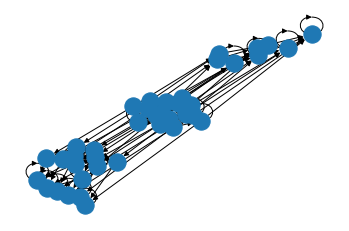

In [11]:
subax1 = plt.subplot()
nx.draw(fragmentNet.graph, with_labels=False, font_weight='bold')
plt.show()

In [12]:
directed = ipycytoscape.CytoscapeWidget()
directed.layout.height = '800px'
directed.layout.width = '970px'
directed.graph.add_graph_from_networkx(fragmentNet.graph, directed=True)

In [13]:
directed.set_layout(name='grid', nodeSpacing=200, edgeLengthVal=100)
directed.set_style([{'selector': "node[type = 'children']", 'css': {
                                'content': 'data(count)',
                                'text-valign': 'top',
                                'color': 'white',
                                'text-outline-width': 2,
                                'text-outline-color': '#FFFFFF',
                                'shape' : 'rectangle',
                                'width':100,
                                'height':100,
                                'border-width':5,
                                'border-color':'#24D5D5',
                                'curve-style':'straight',
                                'background-color': '#FFFFFF',
                                'background-fit':'contain',
                                'background-image':'data(img)'}},
                     
                        {'selector': "node[type = 'root']", 'css': {
                                'content': 'data(count)',
                                'text-valign': 'top',
                                'color': 'white',
                                'text-outline-width': 2,
                                'curve-style':'straight',
                                'text-outline-color': '#FFFFFF',
                                'shape' : 'rectangle',
                                'width':100,
                                'height':100,
                                'border-width':5,
                                'border-color':'#000000',
                                'background-color': '#FFFFFF',
                                'background-fit':'contain',
                                'background-image':'data(img)'}},
                    {'selector': "node[type = 'leave']", 'css': {
                                'content': 'data(count)',
                                'text-valign': 'top',
                                'color': 'white',
                                'text-outline-width': 2,
                                'curve-style':'straight',
                                'text-outline-color': '#FFFFFF',
                                'shape' : 'rectangle',
                                'width':100,
                                'height':100,
                                'border-width':5,
                                'border-color':'#eb4034',
                                'background-color': '#FFFFFF',
                                'background-fit':'contain',
                                'background-image':'data(img)'}},
                   {'selector':"edge.directed", 'css': {
                                "curve-style": "bezier",
                                'width': 4,
                                'label': 'data(reaction)',
                                'line-color': '#8334eb',
                                "target-arrow-shape": "triangle",
                                "target-arrow-color": '#8334eb'}},])
display(directed)

CytoscapeWidget(cytoscape_layout={'name': 'grid', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style=[…

In [14]:
display(directed)

CytoscapeWidget(cytoscape_layout={'name': 'grid', 'nodeSpacing': 200, 'edgeLengthVal': 100}, cytoscape_style=[…